[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/03-cleaning.ipynb)

# Cleaning

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Trace a data problem to its cause before deciding how to fix it.</li>
<li>Record every cleaning step in a ledger that reconciles to the raw row count.</li>
<li>Test whether a leftover quirk actually changes the answer before acting on it.</li>
<li>State the limitations your cleaning choices create.</li>
</ul>
</div>

**Prerequisites:** <a href="../02-data-validation/">Data Acquisition and Validation</a>. **Dataset:** Online Retail II. **Time:** about 35 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

The validation report told us *what* is wrong. Cleaning decides *what to do about it*. Two habits separate trustworthy cleaning from the usual ad-hoc `df = df[df.x > 0]`:

1. **Every step is a decision with evidence.** Say what you found, what you chose, and why.
2. **Every removed row is accounted for.** After each step, record how many rows left and how many remain, so the sum always reconciles to the raw file.

We build the cleaning in the open, step by step, then check that the result is identical to the tested version the later pages import (`mlp_data.retail.clean_retail`).

<div class="admonition note">
<p class="admonition-title">Cleaning is specific to the question</p>
<p>We are cleaning for <em>customer-level</em> modelling: "will this person buy again?". Some choices below (dropping guest checkouts, for example) would be wrong for a question about <em>total shop demand</em>. When we forecast demand later, we will reuse this thinking but clean differently.</p>
</div>

In [2]:
raw = load_retail()
df = raw.copy()
ledger = [("raw file", 0, len(df))]          # (step, rows removed, rows remaining)

def record(step, before):
    ledger.append((step, before - len(df), len(df)))
    print(f"{step:<34} removed {before - len(df):>8,}   remaining {len(df):>9,}")

print(f"{len(df):,} rows to start")

1,067,371 rows to start


## Step 1. The sheet overlap

Validation counted 34,335 exact duplicate rows. Before deleting duplicates, ask **where they come from**, because the answer decides whether deleting is right.

The Excel file is two sheets stacked on top of each other. Within a sheet, time only moves forward, so the one place where it jumps *backwards* is the seam.

In [3]:
backwards = np.flatnonzero((raw["InvoiceDate"].diff() < pd.Timedelta(0)).to_numpy())
seam = int(backwards[0])
print(f"time goes backwards {len(backwards)} time(s), at row {seam:,}")

sheet1, sheet2 = raw.iloc[:seam], raw.iloc[seam:]
overlap_start, overlap_end = sheet2["InvoiceDate"].min(), sheet1["InvoiceDate"].max()
print(f"sheet 2 starts {overlap_start}, sheet 1 ends {overlap_end}: they overlap by {(overlap_end - overlap_start).days + 1} days")

in_a = sheet1[sheet1["InvoiceDate"] >= overlap_start]
in_b = sheet2[sheet2["InvoiceDate"] <= overlap_end]
cols = list(raw.columns)
identical = in_a.sort_values(cols).reset_index(drop=True).equals(in_b.sort_values(cols).reset_index(drop=True))
print(f"rows in the overlap: {len(in_a):,} in sheet 1, {len(in_b):,} in sheet 2; identical row for row: {identical}")
assert identical

total_dups = int(raw.duplicated().sum())
print(f"exact duplicate rows in the raw file: {total_dups:,} = {len(in_a):,} from the overlap + {total_dups - len(in_a):,} repeats within a sheet")

time goes backwards 1 time(s), at row 525,461
sheet 2 starts 2010-12-01 08:26:00, sheet 1 ends 2010-12-09 20:01:00: they overlap by 9 days
rows in the overlap: 22,523 in sheet 1, 22,523 in sheet 2; identical row for row: True


exact duplicate rows in the raw file: 34,335 = 22,523 from the overlap + 11,812 repeats within a sheet


So of the 34,335 "duplicates", **22,523 are one nine-day stretch stored twice**. Deleting them is not a judgement call; leaving them would double-count early December 2010. The remaining 11,812 are repeats *within* a sheet, which is a different question we return to below.

We drop sheet 1's copy of the overlap.

In [4]:
before = len(df)
df = df[~((df.index < seam) & (df["InvoiceDate"] >= overlap_start))]
record("1. sheet overlap", before)

1. sheet overlap                   removed   22,523   remaining 1,044,848


## Step 2. Lines that are not products

Product codes here are five digits with an optional one or two letter suffix (`85123A`). What fails that pattern?

In [5]:
is_product = df["StockCode"].str.fullmatch(retail.PRODUCT_CODE, na=False)
print(f"{is_product.mean():.2%} of lines match the product pattern")
not_product = df[~is_product]
(not_product.groupby("StockCode")
    .agg(lines=("Invoice", "size"), example=("Description", "first"))
    .sort_values("lines", ascending=False).head(8))

99.43% of lines match the product pattern


,lines,example
StockCode,,
POST,2086,POSTAGE
DOT,1425,DOTCOM POSTAGE
M,1398,Manual
C2,277,CARRIAGE
D,173,Discount
S,102,SAMPLES
BANK CHARGES,100,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16


Postage, manual entries, carriage, bank charges, test items: the shop's *administration*, not what customers chose to buy. We drop them.

Is the rule too blunt? Some of these lines did carry a customer and a positive price, so they are real money, just not product demand.

In [6]:
collateral = not_product[not_product["Customer ID"].notna() & (not_product["Quantity"] > 0) & (not_product["Price"] > 0) & ~not_product["Invoice"].str.startswith("C")]
share = (collateral["Quantity"] * collateral["Price"]).sum() / (df["Quantity"].clip(lower=0) * df["Price"].clip(lower=0)).sum()
print(f"{len(collateral):,} such lines, about {share:.1%} of revenue; most common: {collateral['StockCode'].value_counts().head(4).to_dict()}")

2,858 such lines, about 1.5% of revenue; most common: {'POST': 1803, 'M': 691, 'C2': 248, 'ADJUST': 32}


About one and a half percent of revenue, mostly postage. For a "will this customer buy a product again" question, postage is noise. A couple of rare real products (like `SP1002`, a chalkboard) are lost by the rule; with only a handful of lines, that collateral is acceptable and **documented**.

In [7]:
before = len(df)
df = df[is_product[df.index]]
record("2. non-product codes", before)

2. non-product codes               removed    5,993   remaining 1,038,855


## Step 3. Guest checkouts (no customer ID)

Almost a quarter of the raw rows have no `Customer ID`. My first guess was that these were small, casual purchases. **Let's test the guess.**

In [8]:
sale_like = df[~df["Invoice"].str.startswith("C") & (df["Quantity"] > 0) & (df["Price"] > 0)]
guest = sale_like[sale_like["Customer ID"].isna()]
known = sale_like[sale_like["Customer ID"].notna()]
pd.DataFrame({
    "median lines per invoice": [guest.groupby("Invoice").size().median(), known.groupby("Invoice").size().median()],
    "share of sales revenue":   [(guest["Quantity"] * guest["Price"]).sum(), (known["Quantity"] * known["Price"]).sum()],
}, index=["guest (no ID)", "known customer"]).assign(**{"share of sales revenue": lambda t: (t["share of sales revenue"] / t["share of sales revenue"].sum()).map("{:.1%}".format)})

,median lines per invoice,share of sales revenue
guest (no ID),20.00,13.1%
known customer,15.00,86.9%


The guess was wrong. Guest invoices are, if anything, *bigger* (a median of 20 lines against 15) and carry about **one pound in eight** of sales revenue. They are not an ignorable fringe. We still cannot use them *here*, for a reason that has nothing to do with size: without an ID we cannot say that two guest invoices came from the same person, so "buys again" is undefined.

That makes the choice **task-specific and costly**: our customer model never sees about 13% of the shop's product revenue. We note it as a known limitation rather than pretend it away.

In [9]:
before = len(df)
df = df[df["Customer ID"].notna()]
record("3. no customer id", before)

3. no customer id                  removed  232,967   remaining   805,888


## Step 4. Cancellations are behaviour, not purchases

Invoices starting with `C` are cancellations or returns. They are not sales, but they are information (a customer who returns a lot is different). We **set them aside** instead of deleting them. Do they relate to earlier purchases?

In [10]:
df = df.rename(columns={"Invoice": "invoice", "StockCode": "stock_code", "Description": "description", "Quantity": "quantity",
                        "InvoiceDate": "invoice_date", "Price": "unit_price", "Customer ID": "customer_id", "Country": "country"})
df["customer_id"] = df["customer_id"].astype(int)
df["revenue"] = df["quantity"] * df["unit_price"]

is_cancel = df["invoice"].str.startswith("C")
returns = df[is_cancel & (df["quantity"] < 0) & (df["unit_price"] > 0)].copy()

first_buy = df[~is_cancel].groupby(["customer_id", "stock_code"])["invoice_date"].min().rename("first_buy").reset_index()
check = returns.merge(first_buy, on=["customer_id", "stock_code"], how="left")
print(f"{len(returns):,} return lines; {(check['first_buy'] < check['invoice_date']).mean():.0%} are for an item that customer bought earlier")

17,641 return lines; 91% are for an item that customer bought earlier


Nine in ten returns reverse something the customer really bought, so returns are genuine behaviour and belong in a separate table, ready to become a feature later.

In [11]:
before = len(df)
df = df[~is_cancel]
ledger.append(("4. set aside cancellations", int(is_cancel.sum()), len(df)))
print(f"{'4. set aside cancellations':<34} moved   {int(is_cancel.sum()):>8,}   remaining {len(df):>9,}")

4. set aside cancellations         moved     17,641   remaining   788,247


## Step 5. Free items

Some remaining lines have a zero or negative quantity or price without being cancellations. What are they?

In [12]:
bad = df[(df["quantity"] <= 0) | (df["unit_price"] <= 0)]
print(f"{len(bad)} lines, from {bad['customer_id'].nunique()} customers in {bad['invoice'].nunique()} invoices")
print(f"every one has a price of exactly 0: {(bad['unit_price'] == 0).all()}; any with quantity <= 0: {(bad['quantity'] <= 0).any()}")
bad[["invoice", "description", "quantity", "unit_price", "customer_id"]].head(5)

60 lines, from 42 customers in 51 invoices
every one has a price of exactly 0: True; any with quantity <= 0: False


,invoice,description,quantity,unit_price,customer_id
4674,489825,6 RIBBONS EMPIRE,12,0.00,16126
6781,489998,DOOR MAT FAIRY CAKE,2,0.00,15658
18738,490961,CHRISTMAS PUDDING TRINKET POT,1,0.00,14108
18739,490961,CHRISTMAS CRAFT WHITE FAIRY,12,0.00,14108
32916,492079,ANTIQUE LILY FAIRY LIGHTS,8,0.00,15070


All have a real customer, a real product, and a price of **exactly zero**: gifts, samples or replacements. They add no revenue and are not purchases, so they leave the sales table.

<div class="admonition tip">
<p class="admonition-title">Order matters</p>
<p>In the raw file there are many more zero-price and negative lines, with notes like <em>damaged</em> and <em>check</em>: warehouse write-offs. They carry no customer ID, so step 3 had already removed them. What each step finds depends on the steps before it, which is another reason to keep the ledger <em>in order</em>.</p>
</div>

In [13]:
before = len(df)
df = df[(df["quantity"] > 0) & (df["unit_price"] > 0)]
record("5. zero price (free items)", before)

5. zero price (free items)         removed       60   remaining   788,187


## The ledger

Every row is accounted for, and the arithmetic reconciles to the raw file.

In [14]:
ledger_df = pd.DataFrame(ledger, columns=["step", "rows_removed", "rows_remaining"])
ledger_df["share_of_raw"] = ledger_df["rows_removed"] / len(raw)
removed_total = ledger_df["rows_removed"].sum()
assert len(raw) == len(df) + len(returns) + ledger_df.loc[ledger_df["step"] != "4. set aside cancellations", "rows_removed"].sum()
ledger_df.assign(share_of_raw=ledger_df["share_of_raw"].map("{:.1%}".format))

,step,rows_removed,rows_remaining,share_of_raw
0,raw file,0,1067371,0.0%
1,1. sheet overlap,22523,1044848,2.1%
2,2. non-product codes,5993,1038855,0.6%
3,3. no customer id,232967,805888,21.8%
4,4. set aside cancellations,17641,788247,1.7%
5,5. zero price (free items),60,788187,0.0%


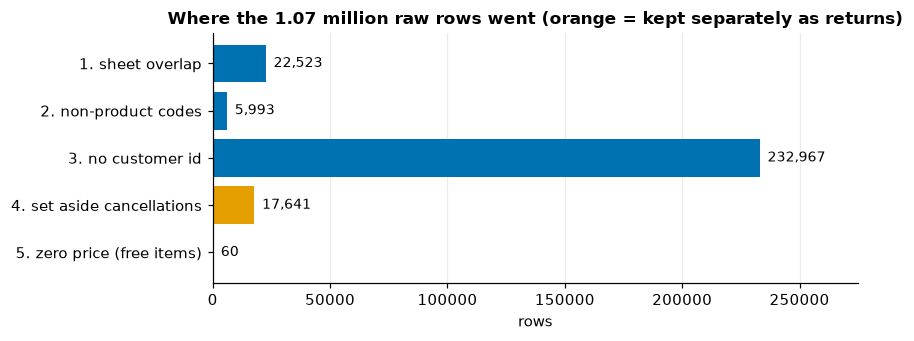

kept: 788,187 purchase lines (74% of raw) and 17,641 return lines, for 5,852 customers


In [15]:
steps = ledger_df.iloc[1:].copy()
fig, ax = plt.subplots(figsize=(8, 3.2))
colors = [style.ORANGE if s.startswith("4.") else style.BLUE for s in steps["step"]]
ax.barh(steps["step"][::-1], steps["rows_removed"][::-1], color=colors[::-1])
for y, v in enumerate(steps["rows_removed"][::-1]):
    ax.text(v, y, f"  {v:,}", va="center", fontsize=9)
ax.set(xlabel="rows", title="Where the 1.07 million raw rows went (orange = kept separately as returns)", xlim=(0, steps["rows_removed"].max() * 1.18))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"kept: {len(df):,} purchase lines ({len(df) / len(raw):.0%} of raw) and {len(returns):,} return lines, for {df['customer_id'].nunique():,} customers")

**Reading the chart.** Guest checkouts dominate the removals by a wide margin; that is the biggest single judgement in the whole cleaning and the one worth revisiting if the project ever needs those customers. The overlap, by contrast, removes a small but *certain* chunk.

## Check it against the tested version

Later pages import `mlp_data.retail.clean_retail` instead of repeating this code. They must be the same thing.

In [16]:
official = retail.clean_retail(raw)
pd.testing.assert_frame_equal(df.reset_index(drop=True), official.sales)
pd.testing.assert_frame_equal(returns.reset_index(drop=True), official.returns)
assert official.log["rows_remaining"].iloc[-1] == len(df)
print("identical to mlp_data.retail.clean_retail: sales, returns and ledger all agree")
sales = official.sales

identical to mlp_data.retail.clean_retail: sales, returns and ledger all agree


## Decisions we deliberately did *not* take

Good cleaning also records what was left alone, and tests whether it matters. Two candidates:

**A. Duplicates within a sheet.** About 11,600 lines remain that exactly repeat another line. They could be double-scans or genuinely repeated items; the data cannot tell us. Rather than guess, measure what they could cost.

In [17]:
dup = sales.duplicated(keep="first")
print(f"{dup.sum():,} repeated lines in {sales.loc[dup, 'invoice'].nunique():,} invoices, touching {sales.loc[dup, 'customer_id'].nunique():,} customers")
print(f"revenue they carry: {sales.loc[dup, 'revenue'].sum() / sales['revenue'].sum():.2%} of all sales")
print("effect on invoice counts (which drive our label and most features): none, since the invoice still exists either way")

11,610 repeated lines in 4,272 invoices, touching 1,580 customers
revenue they carry: 0.33% of all sales
effect on invoice counts (which drive our label and most features): none, since the invoice still exists either way


Under half a percent of revenue and no effect on *whether* a customer bought. We **keep them** and note the sensitivity; it would only matter for a revenue-heavy feature.

**B. Orders cancelled almost immediately.** Customer 12346's £77,183 order on 18 January 2011 was cancelled sixteen minutes later. Counting that as "buying again" would be wrong. How common is it?

In [18]:
inv = retail.invoices(sales)
r = returns.assign(qty=-returns["quantity"])
m = r.merge(sales[["customer_id", "stock_code", "quantity", "invoice_date", "invoice"]],
            left_on=["customer_id", "stock_code", "qty"], right_on=["customer_id", "stock_code", "quantity"], suffixes=("_ret", "_sale"))
m = m[(m["invoice_date_sale"] <= m["invoice_date_ret"]) & (m["invoice_date_ret"] - m["invoice_date_sale"] <= pd.Timedelta(days=1))]
lines_per_invoice = sales.groupby("invoice")["stock_code"].nunique()
reversed_lines = m.groupby("invoice_sale")["stock_code"].nunique()
fully_reversed = reversed_lines[reversed_lines >= lines_per_invoice.reindex(reversed_lines.index)].index
print(f"{len(fully_reversed)} invoices ({len(fully_reversed) / len(inv):.2%}) were fully reversed within a day, carrying {sales.loc[sales['invoice'].isin(fully_reversed), 'revenue'].sum() / sales['revenue'].sum():.1%} of revenue")

# Does it change the label? Recompute 'buys again' for one snapshot, with and without those invoices.
cutoff = pd.Timestamp("2011-03-01")
def label(invoices):
    past = invoices[invoices["date"] < cutoff]
    active = past[past["date"] >= cutoff - pd.Timedelta(days=365)]["customer_id"].unique()
    future = invoices[(invoices["date"] >= cutoff) & (invoices["date"] < cutoff + pd.Timedelta(days=90))]["customer_id"].unique()
    return pd.Series(np.isin(active, future), index=active)
with_all, without = label(inv), label(inv[~inv["invoice"].isin(fully_reversed)])
common = with_all.index.intersection(without.index)
print(f"customers whose label flips: {(with_all[common] != without[common]).sum()} of {len(common):,}")

142 invoices (0.39%) were fully reversed within a day, carrying 2.2% of revenue
customers whose label flips: 0 of 4,257


A fraction of a percent of invoices, a couple of percent of revenue (a few huge orders), and **no label flips at this snapshot**. So we **keep the simple definition** (a genuine invoice is a purchase) and write the limitation down. If this had flipped hundreds of labels, the decision would have been the opposite, and the evidence is what lets us say so. (We tested one snapshot; the same code can be rerun on any other.)

<div class="admonition tip">
<p class="admonition-title">The cleaning checklist</p>
<ol>
<li>For each problem: what did you find, and where does it come from?</li>
<li>What will you do (drop / fix / set aside / keep), and why?</li>
<li>How many rows does it touch, and what share of revenue or of the target?</li>
<li>Does it change the answer? (If not, prefer the simplest choice.)</li>
<li>Is it recorded in a ledger that reconciles to the raw file?</li>
</ol>
</div>

## Check yourself

<details class="question">
<summary>1. Why not simply call <code>df.drop_duplicates()</code> on the raw file?</summary>

It would remove both the 22,523 overlap rows (correct) and the ~11,800 within-sheet repeats (which may be genuine repeated line items), and you would never learn that the two had different causes. Understanding *why* rows are duplicated is what tells you whether deleting them is right.

</details>

<details class="question">
<summary>2. We dropped guest checkouts, yet they hold about one pound in eight of the product revenue. Was that a mistake?</summary>

Not for this question: without an ID there is no 'same customer again', so they cannot enter a customer-level model. But it is a real **limitation** and must be stated: the model describes identified customers, not the whole shop. For a demand forecast we would keep them.

</details>

<details class="question">
<summary>3. Why were cancellations set aside rather than deleted?</summary>

Because they are behaviour: returns reverse real purchases (about nine in ten match something the customer bought earlier), so a return rate can become a useful feature. Deleting them would throw away signal; leaving them in the sales would mix negatives into revenue.

</details>

## Exercise

<details class="question">
<summary>For three cleaning steps, compare the share of <em>rows</em> with the share of <em>revenue</em>. Which one looks very different, and why?</summary>

```python
d = raw.assign(rev=raw["Quantity"] * raw["Price"])
d = d[~d["Invoice"].str.startswith("C")]                  # sales lines only
pos = d["rev"] > 0
total = d.loc[pos, "rev"].sum()
groups = {
    "no customer id":    d["Customer ID"].isna(),
    "non-product code":  ~d["StockCode"].str.fullmatch(retail.PRODUCT_CODE, na=False),
    "sheet overlap":     (d.index < seam) & (d["InvoiceDate"] >= overlap_start),
}
pd.DataFrame({k: {"share of rows": m.mean(), "share of revenue": d.loc[m & pos, "rev"].sum() / total} for k, m in groups.items()}).T.map("{:.1%}".format)
```

Rows and revenue tell different stories. **Non-product lines are about 0.5% of rows but about 4% of revenue** (postage, carriage, manual entries and accounting adjustments are large), so that rule removes far more money than rows. Guest checkouts go the other way, about 23% of rows but about 15% of revenue, because guest lines are cheaper on average. The overlap is the same share of both. Always ask both questions; shares depend on the base you choose, so state it.

</details>

## Recap

- Treat each cleaning step as a decision with **evidence, a count, and a reason**, recorded in a ledger that reconciles to the raw file.
- Find the *cause* of a problem before deleting it: the "duplicates" were mostly one overlapping week, not data-entry errors.
- Set aside what is information (returns) instead of deleting it.
- **Test your assumptions**: guest checkouts were *not* small. Measure whether a leftover quirk changes the answer before spending effort on it.
- Cleaning is specific to the question; write down the limitations it creates.

**Next:** *Exploratory analysis*, where we look at the cleaned data to learn how customers behave.